<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🚀 部署：LangGraph Server · SDK · Assistant · Double-texting

**一句话定位**：`langgraph.json` 指向你的 graph → `langgraph dev`（本地）或 `langgraph build` + Docker（自托管）/ LangSmith Deployment（托管）→ 同一套 SDK 操作 **Assistant / Thread / Run / Store**。
> 覆盖 module-1 deployment + module-6 全部。

</div>

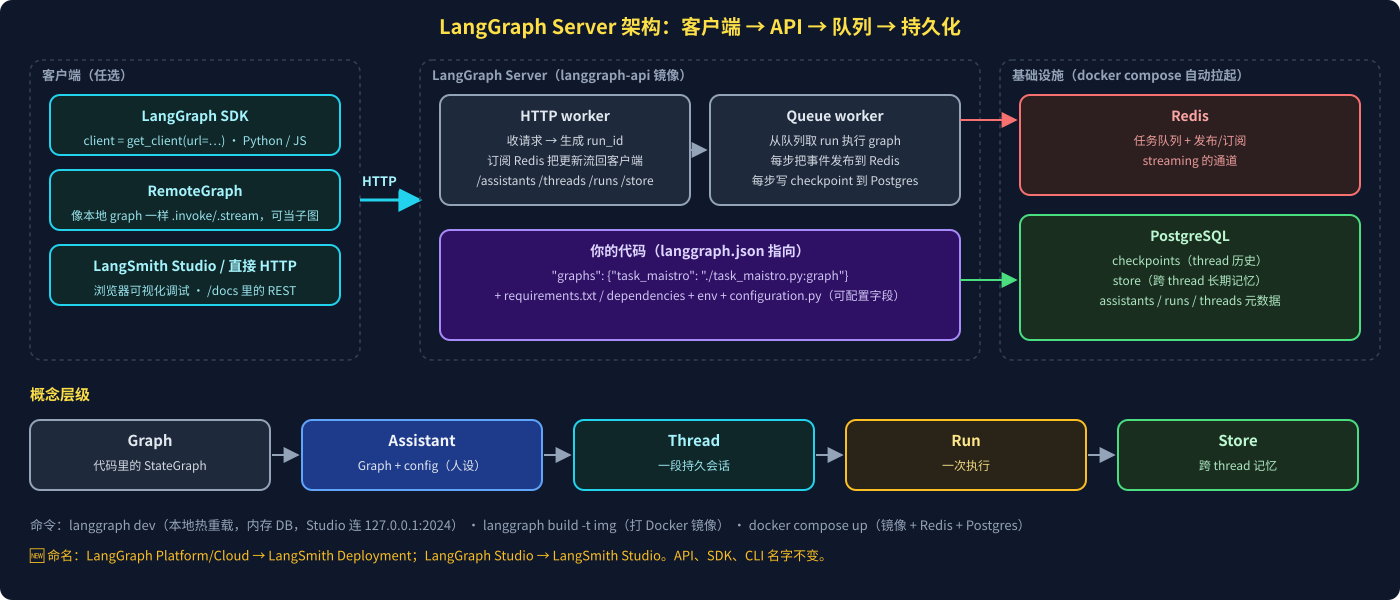

In [ ]:
from IPython.display import SVG
SVG(filename="assets/11_deployment_architecture.svg")

### 1️⃣ 四样东西 + 三条命令

```json
// langgraph.json —— 唯一入口
{
  "graphs": {"task_maistro": "./task_maistro.py:graph"},   // 文件:变量 → assistant/graph_id
  "dependencies": ["."],                                  // 或 requirements.txt
  "env": ".env",
  "python_version": "3.11"
}
```

| 命令 | 做什么 | 存储 |
|---|---|---|
| `langgraph dev` | 本地 API（127.0.0.1:2024）+ 热重载；Studio UI 直接连 | 内存 |
| `langgraph build -t my-image` | 按 langgraph.json 打 Docker 镜像（FastAPI + 你的 graph） | — |
| `docker compose up` | 镜像 + Redis + Postgres 三容器（端口 8123） | Postgres |
| GitHub → LangSmith Deployment | 托管，给你一个 URL | 托管 Postgres |

本地 `graph.invoke(...)` 是 **library**；`langgraph dev` 起的是 **API server**；`langgraph_sdk` 是 **client**。三者是不同层。

### 2️⃣ SDK 速查（`from langgraph_sdk import get_client; client = get_client(url=URL)`）

| 对象 | 常用方法 |
|---|---|
| `assistants` | `search()` · `create(graph_id, config={"configurable": {...}})` · `update(id, config=…)`（版本 +1）· `delete(id)` · `get_versions(id)` |
| `threads` | `create()` · `get_state(tid)` · `update_state(tid, values, checkpoint_id=…)` · `get_history(tid)` · `copy(tid)` · `search()` |
| `runs` | `create(tid, asst, input=…)`（后台）· `wait(tid, asst, input=…)`（阻塞返回结果）· `stream(tid, asst, input=…, stream_mode=…)` · `join(tid, run_id)` · `get` · `cancel` |
| `store` | `put_item(ns, key=, value=)` · `search_items(ns, query=…, limit=…)` · `get_item` · `delete_item` · `list_namespaces()` |

In [ ]:
from langgraph_sdk import get_client
from langchain_core.messages import HumanMessage

client = get_client(url="http://127.0.0.1:2024")     # langgraph dev 的本地地址

thread = await client.threads.create()
# 后台 run：立即返回 run_id，之后 join / get 查状态（pending → success）
run = await client.runs.create(thread["thread_id"], "task_maistro",
                               input={"messages": [HumanMessage("Add a ToDo ...")]},
                               config={"configurable": {"user_id": "Test"}})
await client.runs.join(thread["thread_id"], run["run_id"])

# 流式 run（token 级）
async for chunk in client.runs.stream(thread["thread_id"], "task_maistro", input=..., stream_mode="messages-tuple"):
    if chunk.event == "messages":
        print("".join(d["content"] for d in chunk.data if "content" in d), end="")

# 无状态 run：thread_id=None → 不存 checkpoint、不能 HITL / time travel，适合一次性任务
await client.runs.wait(None, "task_maistro", input=...)

# 历史与分叉（与本地 get_state_history / update_state 对称，见 笔记/09）
states = await client.threads.get_history(thread["thread_id"])
forked = await client.threads.update_state(thread["thread_id"], {...}, checkpoint_id=states[-2]["checkpoint_id"])

### 3️⃣ Assistant = 同一个 graph + 不同 config

```python
personal = await client.assistants.create("task_maistro",
    config={"configurable": {"todo_category": "personal", "user_id": "lance", "task_maistro_role": "..."}})
work = await client.assistants.create("task_maistro", config={"configurable": {"todo_category": "work", ...}})
await client.runs.stream(thread_id, personal["assistant_id"], input=...)   # 用 assistant_id 代替 graph 名
```

| 要点 | 说明 |
|---|---|
| config 何时生效 | 创建时**只是存进 Postgres**；每次 run 时注入每个节点的 `RunnableConfig`（节点内 `Configuration.from_runnable_config(config)` 读取） |
| 记忆隔离 | `todo_category` 进入 store namespace → personal / work 各看各的 |
| 行为差异 | `task_maistro_role` 进入 system prompt |
| 版本 | `assistants.update()` 自动 +1，可回滚；部署时自动有一个默认 assistant |
| 🆕 `context` | 1.x 返回体里同时有 `config.configurable` 与 `context`（对应 `context_schema`）；新代码用 `context=`，老 `configurable` 仍兼容 |

### 4️⃣ Double-texting（同一 thread 上一个 run 没跑完又来一条）

`client.runs.create(..., multitask_strategy=...)`：

| 策略 | 旧 run | 新 run | 适合 |
|---|---|---|---|
| `reject` | 继续 | 409 拒绝 | 一次只许一个问题 |
| `enqueue`（默认） | 跑完 | 排队再跑 | 不丢消息，用户肯等 |
| `interrupt` | 停下，**保留**已完成部分（status `interrupted`） | 立即跑 | 追问要接上进度 |
| `rollback` | 停下并**删除** | 立即跑 | 用户改主意，前面不算 |

只有 Server 提供；纯 library 没有这个问题（单进程顺序执行）。

### 5️⃣ RemoteGraph：把远程部署当本地 graph

```python
from langgraph.pregel.remote import RemoteGraph
remote = RemoteGraph("task_maistro", url="http://localhost:8123")
remote.invoke({"messages": [...]}, config={"configurable": {"thread_id": "t1"}})   # .stream / .get_state 同样可用
parent.add_node("remote_agent", remote)      # 可作为子图嵌入本地 graph → 跨服务组合 agent
```

| | RemoteGraph | SDK client |
|---|---|---|
| 接口 | 与本地 graph 一致 | REST 风格（assistants/threads/runs） |
| 可做子图 | ✅ | ❌ |
| 适合 | 代码里组合 graph | 前端 / 外部系统集成 |

### 🧭 排错 & 实践

| 现象 | 看哪里 |
|---|---|
| `langgraph dev` 起不来 | `langgraph.json` 路径 / `env` 文件 / 依赖没装 |
| run 一直 `pending` | Queue worker 没起（Redis/Postgres 连不上）→ `docker compose logs` |
| 409 Conflict | double-texting `reject`；或 thread 正忙 → 等 `runs.join` |
| 记忆"串号" | namespace 少了 `user_id` / `category` 维度 |
| 本地能跑、部署失败 | 用了 `InMemorySaver`/`InMemoryStore`：部署时**不要自己传 checkpointer/store**，Server 自动注入 Postgres 版 |
| 想看请求细节 | `http://localhost:8123/docs`；LangSmith trace（设 `LANGSMITH_API_KEY`） |

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：**代码 + `langgraph.json` → `langgraph dev` / `build` → Server（HTTP worker + 队列 + Redis + Postgres）**；SDK 四对象 **Assistant（graph+config）/ Thread（会话）/ Run（执行）/ Store（跨 thread 记忆）**；并发用 `multitask_strategy` 四选一；`RemoteGraph` 让远程 graph 像本地一样可组合。

</div>